<a href="https://colab.research.google.com/github/SattikBhaumik/CS156/blob/main/CS156_First_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

I used Claude, and ChatGPT to correct errors in the code. I also used them for writing proper comments. All code and comments were written by me. AI helped me make the code better, cleaner, and also suggested me ideas and improvements on making better tables, lists, plots but I included it only when I understood how it was useful.

#1. Loading Libraries, Data

In [ ]:
#import statements

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
# confusion matrix, ROC-AUC, F1 score
from sklearn import metrics

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier

from scipy.stats import spearmanr

random_state = 42
np.random.seed(random_state)

# to display all columns when printing the data frame
pd.set_option("display.max_columns", None)

In [ ]:
df = pd.read_csv("/content/exoplanets.csv")
print("Shape (rows, columns):", df.shape)

Shape (rows, columns): (9564, 49)


In [ ]:
display(df.head())

,kepid,kepoi_name,kepler_name,koi_disposition,koi_pdisposition,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,koi_fpflag_ec,koi_period,koi_period_err1,koi_period_err2,koi_time0bk,koi_time0bk_err1,koi_time0bk_err2,koi_impact,koi_impact_err1,koi_impact_err2,koi_duration,koi_duration_err1,koi_duration_err2,koi_depth,koi_depth_err1,koi_depth_err2,koi_prad,koi_prad_err1,koi_prad_err2,koi_teq,koi_teq_err1,koi_teq_err2,koi_insol,koi_insol_err1,koi_insol_err2,koi_model_snr,koi_tce_plnt_num,koi_tce_delivname,koi_steff,koi_steff_err1,koi_steff_err2,koi_slogg,koi_slogg_err1,koi_slogg_err2,koi_srad,koi_srad_err1,koi_srad_err2,ra,dec,koi_kepmag
0,10797460,K00752.01,Kepler-227 b,CONFIRMED,CANDIDATE,1.000,0,0,0,0,9.488036,2.780000e-05,-2.780000e-05,170.538750,0.002160,-0.002160,0.146,0.318,-0.146,2.95750,0.08190,-0.08190,616.0,19.5,-19.5,2.26,0.26,-0.15,793.0,NaN,NaN,93.59,29.45,-16.65,35.8,1.0,q1_q17_dr25_tce,5455.0,81.0,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
1,10797460,K00752.02,Kepler-227 c,CONFIRMED,CANDIDATE,0.969,0,0,0,0,54.418383,2.480000e-04,-2.480000e-04,162.513840,0.003520,-0.003520,0.586,0.059,-0.443,4.50700,0.11600,-0.11600,875.0,35.5,-35.5,2.83,0.32,-0.19,443.0,NaN,NaN,9.11,2.87,-1.62,25.8,2.0,q1_q17_dr25_tce,5455.0,81.0,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
2,10811496,K00753.01,NaN,CANDIDATE,CANDIDATE,0.000,0,0,0,0,19.899140,1.490000e-05,-1.490000e-05,175.850252,0.000581,-0.000581,0.969,5.126,-0.077,1.78220,0.03410,-0.03410,10800.0,171.0,-171.0,14.60,3.92,-1.31,638.0,NaN,NaN,39.30,31.04,-10.49,76.3,1.0,q1_q17_dr25_tce,5853.0,158.0,-176.0,4.544,0.044,-0.176,0.868,0.233,-0.078,297.00482,48.134129,15.436
3,10848459,K00754.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,0,1.736952,2.630000e-07,-2.630000e-07,170.307565,0.000115,-0.000115,1.276,0.115,-0.092,2.40641,0.00537,-0.00537,8080.0,12.8,-12.8,33.46,8.50,-2.83,1395.0,NaN,NaN,891.96,668.95,-230.35,505.6,1.0,q1_q17_dr25_tce,5805.0,157.0,-174.0,4.564,0.053,-0.168,0.791,0.201,-0.067,285.53461,48.285210,15.597
4,10854555,K00755.01,Kepler-664 b,CONFIRMED,CANDIDATE,1.000,0,0,0,0,2.525592,3.760000e-06,-3.760000e-06,171.595550,0.001130,-0.001130,0.701,0.235,-0.478,1.65450,0.04200,-0.04200,603.0,16.9,-16.9,2.75,0.88,-0.35,1406.0,NaN,NaN,926.16,874.33,-314.24,40.9,1.0,q1_q17_dr25_tce,6031.0,169.0,-211.0,4.438,0.070,-0.210,1.046,0.334,-0.133,288.75488,48.226200,15.509


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9564 entries, 0 to 9563
Data columns (total 49 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   kepid              9564 non-null   int64  
 1   kepoi_name         9564 non-null   object 
 2   kepler_name        2359 non-null   object 
 3   koi_disposition    9564 non-null   object 
 4   koi_pdisposition   9564 non-null   object 
 5   koi_score          8054 non-null   float64
 6   koi_fpflag_nt      9564 non-null   int64  
 7   koi_fpflag_ss      9564 non-null   int64  
 8   koi_fpflag_co      9564 non-null   int64  
 9   koi_fpflag_ec      9564 non-null   int64  
 10  koi_period         9564 non-null   float64
 11  koi_period_err1    9110 non-null   float64
 12  koi_period_err2    9110 non-null   float64
 13  koi_time0bk        9564 non-null   float64
 14  koi_time0bk_err1   9110 non-null   float64
 15  koi_time0bk_err2   9110 non-null   float64
 16  koi_impact         9201 

The code cell below prints number of unique host stars.

This is fewer than 9,564 because some stars host several KOIs (multi-planet systems).

Hence, the grouping will be done by `kepid` to avoid data leakage of the same star during training and testing.

In [ ]:
print("Unique host stars (kepid):", df["kepid"].nunique())

Unique host stars (kepid): 8214


#2. Pre-training Data Analysis

In [ ]:
# Count missing values in every column, keep only columns that have some,
# and sort from most to least missing.
nan_counts = df.isna().sum()
nan_counts = nan_counts[nan_counts > 0].sort_values(ascending=False)

print("Columns with missing values:\n")
print(nan_counts.to_string())

Columns with missing values:

koi_teq_err1         9564
koi_teq_err2         9564
kepler_name          7205
koi_score            1510
koi_steff_err2        483
koi_slogg_err1        468
koi_slogg_err2        468
koi_srad_err2         468
koi_steff_err1        468
koi_srad_err1         468
koi_period_err2       454
koi_period_err1       454
koi_depth_err1        454
koi_depth_err2        454
koi_time0bk_err1      454
koi_time0bk_err2      454
koi_duration_err2     454
koi_duration_err1     454
koi_impact_err1       454
koi_impact_err2       454
koi_prad_err2         363
koi_teq               363
koi_prad              363
koi_prad_err1         363
koi_impact            363
koi_depth             363
koi_steff             363
koi_model_snr         363
koi_srad              363
koi_slogg             363
koi_tce_delivname     346
koi_tce_plnt_num      346
koi_insol_err1        321
koi_insol             321
koi_insol_err2        321
koi_kepmag              1


There are rows with missing parameters → they are gaps which we cannot include in our analysis.

I am using `koi_depth` to sort out those rows since it comes directly from the transit fit.

In [ ]:
no_fit = df["koi_depth"].isna()
print("Rows with no koi_depth:", no_fit.sum())

Rows with no koi_depth: 363


In [ ]:
# for those rows, checking if they are also empty in the other fitted columns
fit_cols = ["koi_impact", "koi_depth", "koi_prad", "koi_teq",
            "koi_insol", "koi_model_snr", "koi_steff", "koi_slogg", "koi_srad"]
print("For the 363 rows, how many are missing from each fitted column:")
print(df.loc[no_fit, fit_cols].isna().sum().to_string())

# how many of the classes contain these KOIs
print("\nDisposition of the no-fit rows:")
print(df.loc[no_fit, "koi_disposition"].value_counts().to_string())

For the 363 rows, how many are missing from each fitted column:
koi_impact       363
koi_depth        363
koi_prad         363
koi_teq          363
koi_insol        321
koi_model_snr    363
koi_steff        363
koi_slogg        363
koi_srad         363

Disposition of the no-fit rows:
koi_disposition
FALSE POSITIVE    257
CANDIDATE         105
CONFIRMED           1


In [ ]:
# counts for CONFIRMED, FALSE POSITIVE, and CANDIDATE KOIs
class_counts = df["koi_disposition"].value_counts()
print(class_counts.to_string())
print("\nAs fractions:")
print((class_counts / len(df)).round(3).to_string())

koi_disposition
FALSE POSITIVE    4840
CANDIDATE         2367
CONFIRMED         2357

As fractions:
koi_disposition
FALSE POSITIVE    0.506
CANDIDATE         0.247
CONFIRMED         0.246


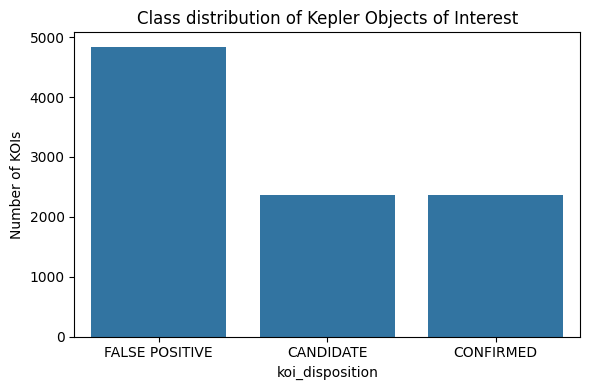


FALSE POSITIVE / CONFIRMED ratio: 2.05


In [ ]:
# bar chart for class distribution
plt.figure(figsize=(6, 4))
sns.barplot(x=class_counts.index, y=class_counts.values)
plt.ylabel("Number of KOIs")
plt.xlabel("koi_disposition")
plt.title("Class distribution of Kepler Objects of Interest")
plt.tight_layout()
plt.show()

# class imbalance ratio for FALSE POSITIVE vs CONFIRMED
print(f"\nFALSE POSITIVE / CONFIRMED ratio: {class_counts["FALSE POSITIVE"] / class_counts["CONFIRMED"]:.2f}")

koi_period: 0 non-positive values, range: 0.242 to 1.3e+05
koi_depth: 1 non-positive values, range: 0 to 1.54e+06
koi_model_snr: 2 non-positive values, range: 0 to 9.05e+03


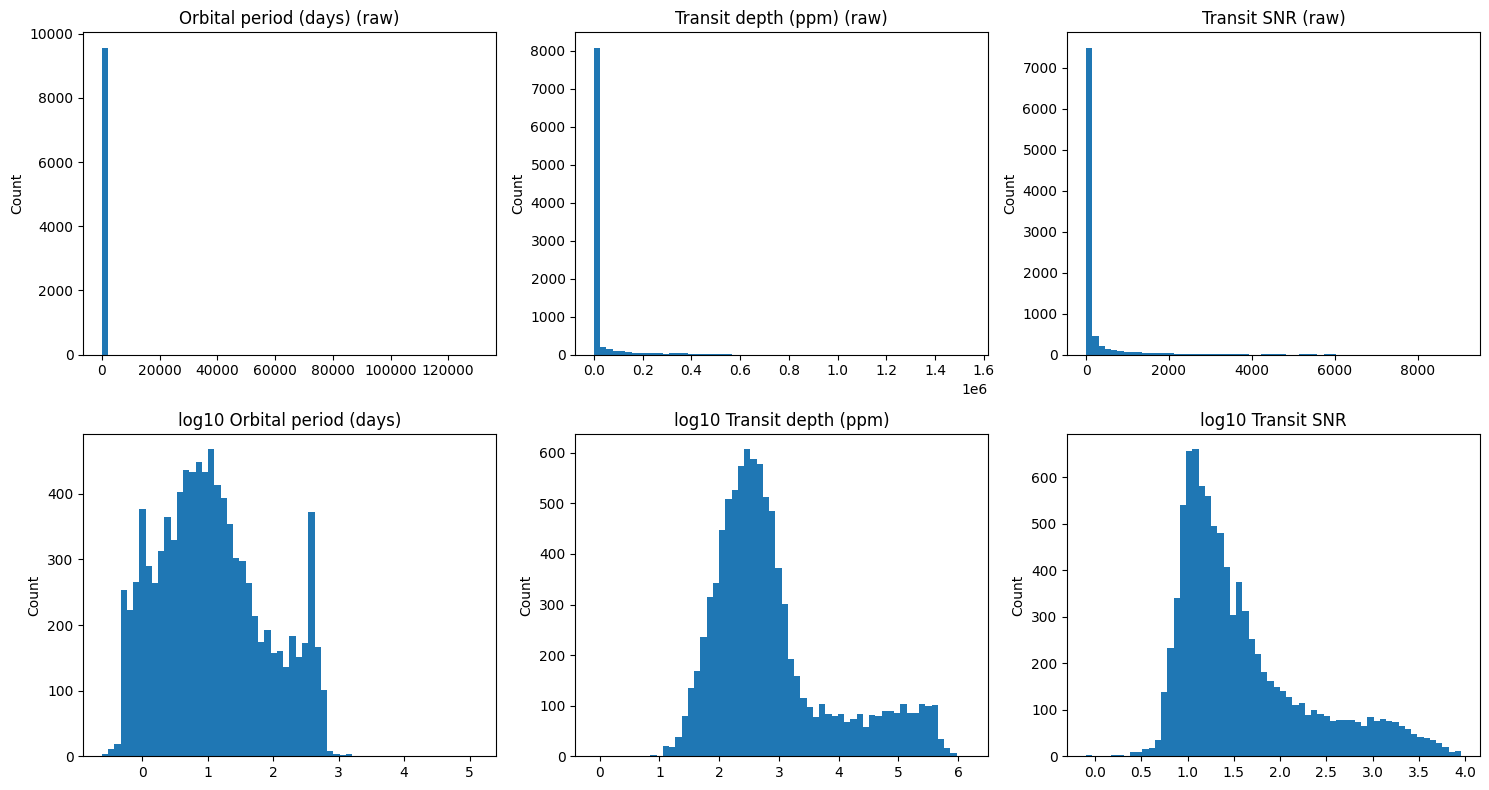

In [ ]:
# we will convert the features that have large range of magnitude into log space
skewed_cols = {
    "koi_period":    "Orbital period (days)",
    "koi_depth":     "Transit depth (ppm)",
    "koi_model_snr": "Transit SNR",
}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, (col, label) in enumerate(skewed_cols.items()):
    values = df[col].dropna()

    # top row: original scale
    axes[0, i].hist(values, bins=60)
    axes[0, i].set_title(f"{label} (raw)")
    axes[0, i].set_ylabel("Count")

    # log10 scale
    # log10 is undefined for values <= 0, so we keep only positive values here.
    positive = values[values > 0]
    axes[1, i].hist(np.log10(positive), bins=60)
    axes[1, i].set_title(f"log10 {label}")
    axes[1, i].set_ylabel("Count")

    # counting non-positive values and feature range
    print(f"{col}: {(values <= 0).sum()} non-positive values, "
          f"range: {values.min():.3g} to {values.max():.3g}")

plt.tight_layout()
plt.show()

## 2.1. Feature groups

The 12 candidate features are grouped by origin and relevance to transit fitting. Some are directly from the flux fit, some are host star properties, and some are derived from the flux depth values and host star properties (planetary features). Units follow the NASA Exoplanet Archive Kepler KOI table.

### Transit features (measured directly from the light curve fit)

| Column | Symbol | Description |
|---|---|---|
| `koi_period` | $P$ | Orbital period in days: the time between successive transits. |
| `koi_duration` | $T_{\rm dur}$ | Transit duration in hours: how long the star stays dimmed. |
| `koi_depth` | $\delta$ | Fractional flux drop at mid-transit, in ppm. For a planet, $\delta \approx (R_p/R_\star)^2$. |
| `koi_impact` | $b$ | Impact parameter, $b = a\cos i / R_\star$. It is $0$ for a central transit and approaches $1$ for a grazing one. |
| `koi_model_snr` | $\mathrm{SNR}$ | Signal-to-noise ratio of the fitted transit model. |

### Stellar features (properties of the host star)

| Column | Symbol | Description |
|---|---|---|
| `koi_steff` | $T_{\rm eff}$ | Effective temperature of the star in K. |
| `koi_slogg` | $\log_{10} g_\star$ | Surface gravity, with $g_\star$ in cm s$^{-2}$. Here $g_\star = GM_\star / R_\star^2$. |
| `koi_srad` | $R_\star$ | Stellar radius in solar radii ($R_\odot$). |
| `koi_kepmag` | $m_{\rm Kep}$ | Apparent magnitude in the Kepler bandpass. Brighter stars (smaller $m_{\rm Kep}$) give cleaner photometry. |

### Derived planet features (computed by the Kepler pipeline from the two groups above)

| Column | Symbol | Description |
|---|---|---|
| `koi_prad` | $R_p$ | Planet radius in Earth radii ($R_\oplus$), from $R_p \approx R_\star \sqrt{\delta}$. |
| `koi_insol` | $S$ | Insolation flux received by the planet, in units of Earth's, with $S \propto R_\star^2\, T_{\rm eff}^4 / a^2$. |
| `koi_teq` | $T_{\rm eq}$ | Equilibrium temperature in K, with $T_{\rm eq} = T_{\rm eff}\sqrt{R_\star / 2a}\,\left[f(1-A_B)\right]^{1/4}$. |

### Correlation Heatmap notes
- $T_{\rm eq} \propto S^{1/4}$ is a strictly increasing function, so the two have Spearman $\rho = 1.00$ (see the heatmap). Hence, `koi_teq` is excluded from all feature groups and `koi_insol` is kept.
- `koi_slogg` and `koi_srad` are strongly anticorrelated ($\rho \approx -0.98$) because $g_\star = GM_\star/R_\star^2$ and stellar mass varies far less than stellar radius across the sample.
- `koi_period` is strongly anti-correlated with $S$ and $T_{\rm eq}$ ($\rho \approx -0.90$) because Kepler's third law gives $a \propto P^{2/3}$, and both quantities decrease as $a$ increases.

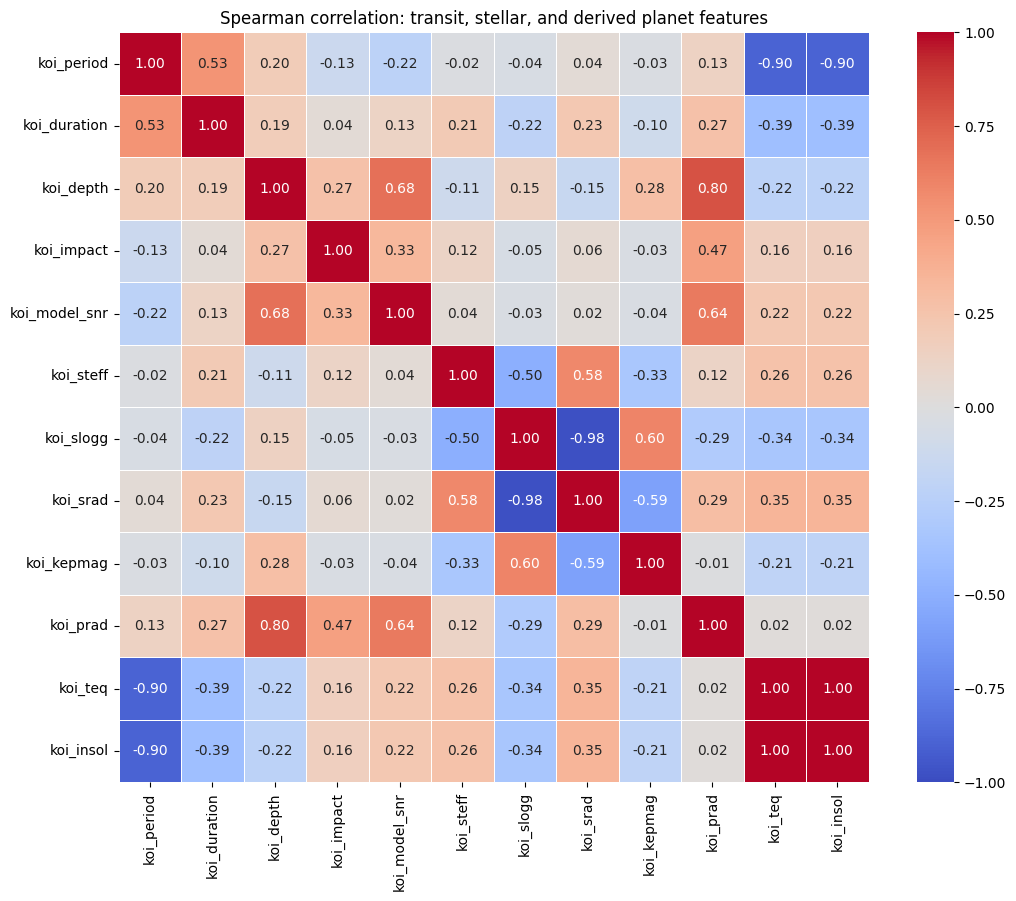

In [ ]:
# features grouping
transit_feats = ["koi_period", "koi_duration", "koi_depth",
                 "koi_impact", "koi_model_snr"]
stellar_feats = ["koi_steff", "koi_slogg", "koi_srad", "koi_kepmag"]
planet_feats  = ["koi_prad", "koi_teq", "koi_insol"]

corr_cols = transit_feats + stellar_feats + planet_feats

'''
CS146 application: Spearman rank correlation instead of Pearson since
some features are heavily skewed with extreme outliers. Pearson would be
dominated by extreme values. Spearman only uses ranks, and log10 transform
does not change the relative ranking of data points.
'''
corr = df[corr_cols].corr(method="spearman")

# correlation heatmap
plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, linewidths=0.5)
plt.title("Spearman correlation: transit, stellar, and derived planet features")
plt.tight_layout()
plt.show()

#3. Setting up Data Frame

In [51]:
'''
We store vetting columns separately columns since using them would lead to
circular definition of labels by the model.
'''
vetting_cols = ["kepoi_name", "kepler_name", "koi_pdisposition", "koi_score",
                "koi_fpflag_nt", "koi_fpflag_ss", "koi_fpflag_co", "koi_fpflag_ec"]
vetting = df[["kepid", "koi_disposition"] + vetting_cols].copy()

# dropping the rows with missing feature values
# these are basically useless to the model since there are no values to train on
no_fit = df["koi_depth"].isna()
unscorable = df[no_fit].copy()
print("Unscorable rows:", len(unscorable))

# dropping the columns which are useless for the model
drop_cols = vetting_cols + ["ra", "dec", "koi_time0bk", "koi_time0bk_err1",
                            "koi_time0bk_err2", "koi_tce_delivname",
                            "koi_tce_plnt_num", "koi_teq_err1", "koi_teq_err2"]

# keeping the index of all the dropped columns for later use
d = df.loc[~no_fit].drop(columns=drop_cols).copy()
print("Dataframe shape after dropping rows and columns:", d.shape)

# dropping error columns
err_cols = [c for c in d.columns if c.endswith("_err1") or c.endswith("_err2")]
d = d.drop(columns=err_cols)
print("Dropped", len(err_cols), "error columns.")

Unscorable rows: 363
Dataframe shape after dropping rows and columns: (9201, 32)
Dropped 18 error columns.


## 3.1. Feature: transit duration ratio

A real planet transiting a star must produce a transit of a specific length which is set by the orbit and the orbit is set by the star's gravity. If the observed duration disagrees with the duration expected for the target star, the signal may come from a different object, such as a background eclipsing binary. This feature measures that disagreement.

**1: eliminating stellar mass.** The catalog has no stellar mass column, but it has surface gravity $g_\star = G M_\star / R_\star^2$, so $G M_\star = g_\star R_\star^2$. Substituting into Kepler's third law, $P^2 = 4\pi^2 a^3 / (G M_\star)$, gives

$$\left(\frac{a}{R_\star}\right)^3 = \frac{G M_\star P^2}{4\pi^2 R_\star^3} = \frac{g_\star P^2}{4\pi^2 R_\star}$$

with $g_\star = 10^{x}$, where $x$ is the `koi_slogg` column ($\log_{10} g_\star$), $g_\star$ in cm s$^{-2}$, $R_\star$ in cm, and $P$ in seconds.

**2: expected duration.** For a circular orbit, a central transit ($b = 0$), and a planet much smaller than its star, the star-crossing time is

$$T_{\rm exp} \approx \frac{P}{\pi}\,\frac{R_\star}{a}$$

**3: the transit duration ratio feature.** The observed duration is compared to the expected one on a log scale, so that over-long and over-short transits are symmetric around zero:

$$\mathrm{Duration Ratio} = \log_{10}\!\left(\frac{T_{\rm obs}}{T_{\rm exp}}\right)$$

**Example:** A Sun-like star with $P = 365$ d has $a/R_\star \approx 215$, so $T_{\rm exp} \approx 13$ h, which matches the real Earth transit.

**Notes:**

- A value of $0$ means the observed duration matches a central transit across this star.
- For a true planet on a circular orbit, a nonzero impact parameter shortens the transit by roughly $T \approx T_{\rm exp}\sqrt{1 - b^2}$, so the feature should sit at or slightly below $0$. The observed median is $-0.033$.

**Limitations:**

- The approximation ignores the planet-to-star radius ratio, the exact $\arcsin$ geometry, and orbital eccentricity.
- The errors on `koi_slogg` and `koi_srad` propagate into $a/R_\star$, so the feature becomes noisy.
- The distribution has a heavy lower tail (minimum $-2.66$, standard deviation $0.349$).

In [ ]:
# transit duration variable
# solar radius in cm
R_SUN_CM = 6.957e10
SEC_PER_DAY = 86400.0

# koi_slogg is log10(g), g in cm/s^2
g = 10 ** d["koi_slogg"]
# stellar radius in cm
R_star = d["koi_srad"] * R_SUN_CM
# period in seconds
P = d["koi_period"] * SEC_PER_DAY

# a/R_star from Kepler's third law, rewritten using g instead of stellar mass
a_over_R = (g * P**2 / (4 * np.pi**2 * R_star)) ** (1/3)

# Expected duration (hours) for a central transit on a circular orbit
T_expected_hr = (d["koi_period"] * 24) / (np.pi * a_over_R)

# Ratio of observed to expected duration
d["log_dur_ratio"] = np.log10(d["koi_duration"] / T_expected_hr)
print(d["log_dur_ratio"].describe().round(3).to_string())

count    9201.000
mean       -0.063
std         0.349
min        -2.661
25%        -0.195
50%        -0.033
75%         0.101
max         1.438


In [ ]:
# storing new log columns
log_map = {"koi_period":    "log_period",
           "koi_depth":     "log_depth",
           "koi_duration":  "log_duration",
           "koi_model_snr": "log_snr",
           "koi_prad":      "log_prad",
           "koi_insol":     "log_insol"}

for col, new_col in log_map.items():
    n_bad = (d[col] <= 0).sum()
    # Any value <= 0 is clipped to the floor,
    # this is done so log10 does not return an error
    floor = d.loc[d[col] > 0, col].min()
    d[new_col] = np.log10(d[col].clip(lower=floor))
    print(f"{col}: {n_bad} non-positive values clipped to {floor:.3g}")

# dropping the original columns versions so the model only uses the log space ones
d = d.drop(columns=list(log_map.keys()))

koi_period: 0 non-positive values clipped to 0.242
koi_depth: 1 non-positive values clipped to 0.8
koi_duration: 0 non-positive values clipped to 0.052
koi_model_snr: 2 non-positive values clipped to 0.8
koi_prad: 0 non-positive values clipped to 0.08
koi_insol: 1 non-positive values clipped to 0.02


In [ ]:
# dropping NaNs (infinite values)
num = d.select_dtypes(include=[np.number])
print("Infinite values:", np.isinf(num).sum().sum())

print("\nFinal Dataframe shape:", d.shape)
print("\nRemaining NaNs per column:")
print(d.isna().sum()[d.isna().sum() > 0].to_string())

print("\nColumns:", list(d.columns))
print("\nDisposition counts after dropping unfitted rows:")
print(d["koi_disposition"].value_counts().to_string())

Infinite values: 0

Final Dataframe shape: (9201, 15)

Remaining NaNs per column:
koi_kepmag    1

Columns: ['kepid', 'koi_disposition', 'koi_impact', 'koi_teq', 'koi_steff', 'koi_slogg', 'koi_srad', 'koi_kepmag', 'log_dur_ratio', 'log_period', 'log_depth', 'log_duration', 'log_snr', 'log_prad', 'log_insol']

Disposition counts after dropping unfitted rows:
koi_disposition
FALSE POSITIVE    4583
CONFIRMED         2356
CANDIDATE         2262


#4. Features grouping

In [ ]:
# we will use CANDIDATES subset later for model classification and performance comparison
candidates = d[d["koi_disposition"] == "CANDIDATE"].copy()
labeled = d[d["koi_disposition"] != "CANDIDATE"].copy()

# target labels for training and tetsing: CONFIRMED = 1, FALSE POSITIVE = 0
labeled["target"] = (labeled["koi_disposition"] == "CONFIRMED").astype(int)

print("Labeled rows:  ", len(labeled))
print("Candidate rows:", len(candidates))
print(labeled["target"].value_counts())

# Feature groups: based on relevance to transit fitted light curve
# G1: transit light curve fit gives these directly
G1 = ["log_period", "log_duration", "log_depth", "koi_impact", "log_snr"]

# G2: host star properties and the duration-ratio variable/feature
G2 = G1 + ["koi_steff", "koi_slogg", "koi_srad", "koi_kepmag", "log_dur_ratio"]

# G3: derived planet properties
# koi_teq is not included since it duplicates log_insol --> 1:1 correlation
G3 = G2 + ["log_prad", "log_insol"]

groups = {"G1": G1, "G2": G2, "G3": G3}

Labeled rows:   6939
Candidate rows: 2262
target
0    4583
1    2356
Name: count, dtype: int64


## 4.1. Train/test split: stratified and grouped by host star

**Why grouping is needed:** Several KOIs can orbit the same star (same `kepid`), and they share identical stellar features ($T_{\rm eff}$, $\log_{10} g_\star$, $R_\star$, $m_{\rm Kep}$). A random row-level split would put one planet in training and its sibling in testing. The model could then score well by recognizing the star, not by learning transit physics, which inflates every test metric. That's why I am splitting by star, so that all KOIs of the same star land on the same side.

**Method:** Let $N = 6939$ be the labeled KOIs (CONFIRMED and FALSE POSITIVE), each with a class $y_i \in \{0, 1\}$ and a group label $s_i$ (its star). `StratifiedGroupKFold` with $K = 5$ assigns every group $G_s = \{i : s_i = s\}$ to exactly one fold $f(s) \in \{1, \dots, 5\}$. Each group is placed greedily, largest class-imbalance first, into the fold that makes the class proportions across folds most uniform. Writing $n_{f,c}$ for the number of class-$c$ samples in fold $f$, the idea is to have

$$\frac{n_{f,1}}{n_{f,0} + n_{f,1}} \;\approx\; \bar{p} = \frac{1}{N}\sum_{i=1}^{N} y_i \quad \text{for every fold } f,$$

subject to the hard constraint

$$s_i = s_j \;\Rightarrow\; f(s_i) = f(s_j).$$

The constraint is exact. The proportion condition is only approximate, because a star with several KOIs moves as one block and cannot be split to balance the classes perfectly.

**One fold as the test set:** I take the first of the five folds as the test set. This gives roughly a $1/5$ or $20\%$ test fraction and $4/5$ or $80\%$ training fraction. The actual sizes differ slightly from 80/20 because folds are built from whole stars:

$$N_{\rm train} = 5538 \;(79.8\%), \qquad N_{\rm test} = 1401 \;(20.2\%).$$

**Checks:**

| Check | Result |
|---|---|
| Fraction CONFIRMED, train | $0.339$ |
| Fraction CONFIRMED, test | $0.343$ |
| Difference | $0.004$ |
| Stars appearing in both sets | $0$ |

The class balance is preserved to within $0.4$ percentage points (0.343-0.339 = 0.004 \& 0.004*100 = 0.4), and no star contributes to both sets:

$$\{s_i : i \in \text{train}\} \cap \{s_j : j \in \text{test}\} = \varnothing.$$

**Reuse in cross-validation:** The same splitter, with $K = 5$ and a fixed seed, builds the cross-validation folds inside the training set. Every model and feature group is scored on identical folds, which makes a fair comparison.

**Limitation:** Stratification is approximate, and a single held-out fold gives one test estimate with no variance of its own.

In [ ]:
# 5 folds splitting
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True,
                                random_state=random_state)

train_idx, test_idx = next(splitter.split(labeled, labeled["target"],
                                          groups=labeled["kepid"]))

train = labeled.iloc[train_idx]
test  = labeled.iloc[test_idx]

print("Train rows:", len(train))
print("Test rows:", len(test))
print("Fraction CONFIRMED in train:", round(train["target"].mean(), 3))
print("Fraction CONFIRMED in test: ", round(test["target"].mean(), 3))
print("Stars in both sets:", len(set(train["kepid"]) & set(test["kepid"])))

Train rows: 5538
Test rows: 1401
Fraction CONFIRMED in train: 0.339
Fraction CONFIRMED in test:  0.343
Stars in both sets: 0


#5. reference functions



Every model is wrapped in a scikit-learn `Pipeline` so that all data-dependent preprocessing is learned only from the data the pipeline is fit on. During cross-validation, each fold therefore computes its own medians and scaling statistics, and nothing leaks from the validation fold. Furthermore, the imputer and scaler is in each fold instead of once on all the data which makes the cross-validation better.

**Note:** Even though there is only one NaN value in `koi_kepmag`, I am using a median substitution else the logistic regression and naive bayes will crash during training. I thought that it would be better to do that since I will be applying the model to CANDIDATES subset which might have similar NaN values. Also, if one wanted to include the error columns, there are NaN values where median substitution could be useful.

**1: median subsitution/imputation (for all models):** For feature $j$, a missing value is replaced by the median of that column in the fitting data:

$$x_{ij} \leftarrow \tilde{x}_j = \operatorname{median}\{x_{kj} : k \in \text{fit set}\}$$

The median is used instead of the mean because several features are heavy-tailed, so the mean would be pulled by a few extreme values. Only one value in the cleaned data is missing (`koi_kepmag`), so this step has almost no effect.

**2: standardisation (Logistic Regression and Naive Bayes only):** Each feature is converted to a z-score using the fit-set mean $\mu_j$ and standard deviation $s_j$:

$$z_{ij} = \frac{x_{ij} - \mu_j}{s_j}$$

Logistic regression needs this because its L2 penalty $\tfrac{1}{2}\lVert\boldsymbol\beta\rVert^2$ treats all coefficients equally, so features must share a scale for the penalty to be fair. XGBoost does not need this standardisation since Trees split on thresholds and are not changed by monotonic rescaling.

**3: handling class imbalance:** The training set has $N_0$ false positives and $N_1$ confirmed planets, with $N_0 / N_1 \approx 1.95$. Each model compensates in its own way.

*Logistic regression* uses `class_weight="balanced"`, which weights each class inversely to its frequency, $w_c = \dfrac{N}{2N_c}$, and minimizes the weighted, regularized log-loss:

$$\min_{\boldsymbol\beta,\,\beta_0}\; \frac{1}{2}\lVert\boldsymbol\beta\rVert^2 + C\sum_{i=1}^{N} w_{y_i}\,\ell_i, \qquad \ell_i = -y_i\log p_i - (1-y_i)\log(1-p_i)$$

where $p_i = \sigma(\beta_0 + \boldsymbol\beta^\top \mathbf z_i)$. Larger $C$ means weaker regularization.

*XGBoost* uses `scale_pos_weight`, which multiplies the loss of every positive example by

$$\mathrm{scale\_pos\_weight} = \frac{N_0}{N_1} = \frac{4583 \text{ (full labeled set)}}{2356} \approx 1.926$$

It is computed in the code from the training split (`scale_pos_weight` ≈ 1.95), so it is the same ratio up to the small difference between the training split and the full labeled set. This makes the total weight of the two classes equal.

**Note: Gaussian Naive Bayes** has no reweighting. It uses the empirical class priors $P(y=c) = N_c / N$, which is why its probabilities lean toward the majority class and its decision at the 0.5 threshold behaves differently from Logistic Regression.

In [ ]:
# Imbalance weight for XGBoost from training data: negatives / positives
SCALE_POS_WEIGHT = (train["target"] == 0).sum() / (train["target"] == 1).sum()

def build_pipeline(model_name, **params):
    # for every model: all NaNs are replaced with the column median.
    # the medians are learned only from the data it is fit on.
    steps = [("imputer", SimpleImputer(strategy="median"))]

    if model_name == "LR":
        steps.append(("scaler", StandardScaler()))   # LR needs features on one scale
        model = LogisticRegression(class_weight="balanced", max_iter=2000, **params)

    elif model_name == "NB":
        steps.append(("scaler", StandardScaler()))
        model = GaussianNB(**params)

    elif model_name == "XGB":
        # Trees split on threshold
        model = XGBClassifier(scale_pos_weight=SCALE_POS_WEIGHT,
                              eval_metric="logloss", random_state=random_state, **params)

    steps.append(("model", model))
    return Pipeline(steps)

In [ ]:
def evaluate(pipeline, X, y, name="Model"):
    # probability of CONFIRMED (for ROC-AUC) and threshold at 0.5 (for the rest)
    y_prob = pipeline.predict_proba(X)[:, 1]
    y_pred = (y_prob >= 0.5).astype(int)

    # confusion matrix: TN, FP, FN, TP
    tn, fp, fn, tp = metrics.confusion_matrix(y, y_pred).ravel()

    results = {"Model": name, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
               "Accuracy":  metrics.accuracy_score(y, y_pred),
               "Precision": metrics.precision_score(y, y_pred),
               "Recall":    metrics.recall_score(y, y_pred),
               "F1":        metrics.f1_score(y, y_pred),
               "ROC-AUC":   metrics.roc_auc_score(y, y_prob)}

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
    # upper left = TN, upper right = FP, lower left = FN, lower right = TP
    cell_text = [[f"TN\n{tn}", f"FP\n{fp}"],
                 [f"FN\n{fn}", f"TP\n{tp}"]]
    sns.heatmap([[tn, fp], [fn, tp]], annot=cell_text, fmt="", cbar=False, cmap="Blues",
                xticklabels=["Not planet (0)", "Planet (1)"],
                yticklabels=["Not planet (0)", "Planet (1)"], ax=ax1)

    ax1.set_xlabel("Predicted"); ax1.set_ylabel("True")
    ax1.set_title(f"{name}: confusion matrix")
    fpr, tpr, _ = metrics.roc_curve(y, y_prob)

    ax2.plot(fpr, tpr, label=f"AUC = {results['ROC-AUC']:.3f}")
    ax2.plot([0, 1], [0, 1], "--", color="grey", label="Random guess")
    ax2.set_xlabel("False Positive Rate"); ax2.set_ylabel("True Positive Rate")
    ax2.set_title(f"{name}: ROC curve"); ax2.legend()

    plt.tight_layout()
    plt.show()
    return results

#6. Cross Validation

## 6.1. cross-validation folds, and hyperparameter grids

Each group is a superset of the previous one, so any change in score between groups can be attributed to the features that were added.

| Group | Added features | Total |
|---|---|---|
| G1 | Transit fit: $\log_{10}P$, $\log_{10}T_{\rm dur}$, $\log_{10}\delta$, $b$, $\log_{10}\mathrm{SNR}$ | 5 |
| G2 | Stellar: $T_{\rm eff}$, $\log_{10} g_\star$, $R_\star$, $m_{\rm Kep}$, the duration ratio $\mathrm{DR}$ | 10 |
| G3 | Derived planet: $\log_{10}R_p$, $\log_{10}S$ | 12 |

## Cross-validation

The training set is split once into $K = 5$ folds with `StratifiedGroupKFold`, grouped by host star. For each fold $k$, a model is fit on the other four folds and scored on fold $k$. The reported score for a (model, group, setting) cell is the mean and standard deviation over folds:

$$\overline{\mathrm{AUC}} = \frac{1}{K}\sum_{k=1}^{K}\mathrm{AUC}_k, \qquad s = \sqrt{\frac{1}{K}\sum_{k=1}^{K}\left(\mathrm{AUC}_k - \overline{\mathrm{AUC}}\right)^2}$$

The folds are built once and reused for every model, group, and setting. The best setting in each cell is the one with the highest $\overline{\mathrm{AUC}}$.

## Hyperparameter grids

| Model | Parameter | Values | Role |
|---|---|---|---|
| Logistic Regression | $C$ | $0.01,\ 0.1,\ 1,\ 10,\ 100$ | Inverse regularization strength. Small $C$ means a strong penalty. |
| Naive Bayes | $\epsilon$ (`var_smoothing`) | $10^{-9},\ 10^{-6},\ 10^{-3},\ 10^{-1},\ 1$ |  prevent numerical errors and artificially regularize the model's variance |
| XGBoost | `max_depth` | $3,\ 5,\ 7$ | Maximum tree depth, which controls the order of feature interactions. |
| XGBoost | $\eta$ (`learning_rate`) | $0.03,\ 0.1,\ 0.3$ | shrinkage factor scaling contribution of newly added tree to model's final prediction |

**Naive Bayes smoothing.** `var_smoothing` adds a fraction of the largest feature variance to every per-class variance:

$$\sigma_{c,j}^2 \;\leftarrow\; \sigma_{c,j}^2 + \epsilon\,\max_{j'}\operatorname{Var}(x_{j'})$$

Larger $\epsilon$ widens every Gaussian, which reduces the overconfidence that comes from multiplying many near-redundant likelihoods.

**XGBoost update rule.** Trees are added sequentially, each scaled by the learning rate ($\eta$):

$$F_m(\mathbf x) = F_{m-1}(\mathbf x) + \eta\, f_m(\mathbf x)$$

A smaller $\eta$ needs more trees but generalizes better. The grid is $3 \times 3 = 9$ combinations, spaced by about 3x in $\eta$ because its effect is multiplicative.

**Number of trees.** This is not in the grid. For each fold, an inner grouped split of the training portion is used for early stopping: trees are added until the inner-validation log-loss has not improved for 30 rounds (see `fit_model` method below in XGBoost section). The final model uses the median tree count across folds.

**Grid size.** The total number of fits is

$$\underbrace{(5 + 5 + 9)}_{\text{settings}} \times \underbrace{3}_{\text{groups}} \times \underbrace{5}_{\text{folds}} = 285.$$

## Limitations:

- The grid is deliberately coarse ("light tuning") since a finer grid would increase time complexity.
- The best LR value ($C = 100$) and the best XGBoost learning rate ($\eta = 0.03$) both lie at the edge of their grids, so a wider search could give a small further gain. $\eta = 0.01$ might have done better but with more trees.
- Other XGBoost parameters (`subsample`, `colsample_bytree`, `min_child_weight`, etc.) were left at their defaults due to the small dataset. A finer tuned model would have values for these settings.

In [ ]:
groups = {"G1": G1, "G2": G2, "G3": G3}
for name, cols in groups.items():
    print(f"{name}: {len(cols)} features")

# Labels array and groups array
y_train = train["target"].values
groups_train = train["kepid"].values

'''
5-fold cross validation
Every model and group reuses these exact folds, so differences in performance
is due to the model and features and not from the train/test split
'''
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=random_state)
folds = list(cv.split(train, y_train, groups=groups_train))

# hyperparameter grids
param_grids = {
    # C = inverse regularization strength. Small C = strong penalty, simpler model
    "LR":  [{"C": c} for c in [0.01, 0.1, 1, 10, 100]],

    # var_smoothing adds (value * largest feature variance) to every variance
    # Larger values flatten the Gaussians which helps with outliers
    "NB":  [{"var_smoothing": v} for v in [1e-9, 1e-6, 1e-3, 1e-1, 1.0]],

    # 3 depths * 3 learning rates = 9 combinations
    "XGB": [{"max_depth": d, "learning_rate": lr}
            for d in [3, 5, 7] for lr in [0.03, 0.1, 0.3]],
}

G1: 5 features
G2: 10 features
G3: 12 features


##6.2. XGBoost: gradient boosting and early stopping

### The model

XGBoost builds an additive ensemble of $M$ regression trees. Each tree $f_m$ maps a feature vector $\mathbf{x}$ to a leaf score, and the raw prediction (log-odds) is the sum:

$$F_M(\mathbf{x}) = \sum_{m=1}^{M} \eta\, f_m(\mathbf{x}), \qquad p(\mathbf{x}) = \sigma\!\big(F_M(\mathbf{x})\big) = \frac{1}{1 + e^{-F_M(\mathbf{x})}}$$

Here $\eta$ is the learning rate. Trees are added one at a time. At step $m$, the new tree $f_m$ is chosen to minimize a regularized objective, using a second-order Taylor expansion of the loss around the current prediction $F_{m-1}$:

$$\mathcal{L}^{(m)} \approx \sum_{i=1}^{N} w_{y_i}\left[g_i f_m(\mathbf{x}_i) + \tfrac{1}{2} h_i f_m(\mathbf{x}_i)^2\right] + \Omega(f_m), \qquad \Omega(f) = \gamma T + \tfrac{1}{2}\lambda \sum_{j=1}^{T} v_j^2$$

with

$$g_i = \frac{\partial \ell(y_i, F_{m-1})}{\partial F_{m-1}} = p_i - y_i, \qquad h_i = \frac{\partial^2 \ell(y_i, F_{m-1})}{\partial F_{m-1}^2} = p_i(1 - p_i)$$

where $\ell$ is the log-loss, $T$ is the number of leaves, $v_j$ are the leaf scores, $\gamma$ penalizes extra leaves, and $\lambda$ is an L2 penalty on leaf scores. The weight $w_{y_i}$ equals `scale_pos_weight` $\approx 1.95$ for confirmed planets and $1$ otherwise. For a fixed tree structure, the optimal score of leaf $j$ has a closed form:

$$v_j^{*} = -\frac{\sum_{i \in I_j} w_i g_i}{\sum_{i \in I_j} w_i h_i + \lambda}$$

where $I_j$ is the set of samples in leaf $j$. Splits are chosen greedily by the gain in the objective. Each tree therefore corrects the errors of the ensemble so far, which is a gradient descent step in function space.

Boosting reduces **bias** by fitting residual structure, while the learning rate and the leaf penalties control **variance**.

### Choosing the number of trees: early stopping on an inner split

The number of trees $M$ is not in the hyperparameter grid. It is chosen separately inside every cross-validation fold, so the outer validation fold never affects it:

1. **Inner split:** The training portion of the fold is split again with `StratifiedGroupKFold`, grouped by `kepid`. One of five inner folds (about 20%) becomes the inner-validation set, so no star appears on both sides.
2. **Probe model:** Up to 1000 trees are grown on the inner-train part. After each tree, the inner-validation log-loss is computed:

$$\mathrm{LL}_m = -\frac{1}{N_{\rm val}}\sum_{i \in \text{val}}\Big[y_i \log p_i^{(m)} + (1 - y_i)\log\big(1 - p_i^{(m)}\big)\Big]$$

Training stops when $\mathrm{LL}_m$ has not improved for 30 consecutive rounds (chosen arbitrarily between the standard 10-50 rounds). The selected size is

$$M^{*} = \arg\min_{m}\ \mathrm{LL}_m$$

3. **Refit:** A fresh pipeline with $M^{*}$ trees is fit on the full training portion of the fold and scored on the outer validation fold.

For the final model, the tree count is the **median of $M^{*}$ across the five folds** (345 for G3, with depth 5 and $\eta = 0.03$) (see `Model Fitting` section below). It is then fixed to avoid early stopping and test-set peeking, happens at the end.

### Notes:

- **There is no leakage** because early stopping uses its own inner split and the outer fold's score is not tuned on the data it is scored on.
- **Grouped inner split:** A random inner split would let sibling KOIs of one star sit on both sides, which would make the validation loss better.
- **Imputer inside:** The inner imputer is fit on inner-train only, for the same reason as above.
- I used log-loss for stopping instead of AUC since log-loss is smooth and responds to every tree whereas AUC only changes when two examples swap rank.

### Limitations:

- The inner validation set is about $0.2 \times 0.8 \times 5538 \approx 900$ rows, so $M^{*}$ is itself noisy which gets reduced if we take the median over five folds.
- Early stopping uses log-loss, while model selection uses ROC-AUC. A model can have a worse log-loss but a better AUC so the tree count that is best for one might not be best for the other.
- The probe model is trained on about 80% of the fold's training rows but the refit uses all of them. In other words, the probe model uses an inner-train set that is 20% smaller than the refit set, so $M^{*}$ is slightly less than what the full 100% could use.

In [ ]:
def fit_model(model_name, params, X_tr, y_tr, groups_tr):
    """
    fit one model on one training fold.
    Returns: (fitted pipeline, n_trees).

    Logistic Regression & Naive Bayes: only fitting

    XGB uses early stopping on an inner split:
      1. split the training fold again: ~80% inner-train, ~20% inner-validation
         (still grouped by kepid, so no star leaks into the inner validation set).
      2. probe model: grow up to 1000 trees on inner-train; stop when inner-validation
         log-loss has not improved for 30 rounds.
      3. refit on the FULL training fold with that number of trees.

    The outer validation fold is never used to choose the number of trees.
    """
    if model_name != "XGB":
        pipe = build_pipeline(model_name, **params)
        pipe.fit(X_tr, y_tr)
        return pipe, None

    # inner grouped split (first of 5 folds as inner validation)
    inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=random_state)
    in_tr, in_val = next(inner.split(X_tr, y_tr, groups=groups_tr))

    # mediam subsitution from inner-train only
    imputer = SimpleImputer(strategy="median").fit(X_tr.iloc[in_tr])
    X_in_tr  = imputer.transform(X_tr.iloc[in_tr])
    X_in_val = imputer.transform(X_tr.iloc[in_val])

    # probe model with early stopping
    probe = XGBClassifier(n_estimators=1000, early_stopping_rounds=30,
                          scale_pos_weight=SCALE_POS_WEIGHT, eval_metric="logloss",
                          random_state=random_state, **params)
    probe.fit(X_in_tr, y_tr[in_tr],
              eval_set=[(X_in_val, y_tr[in_val])], verbose=False)
    best_n = probe.best_iteration + 1      # best_iteration counts from 0

    # refit the normal pipeline on the whole training fold
    pipe = build_pipeline("XGB", n_estimators=best_n, **params)
    pipe.fit(X_tr, y_tr)
    return pipe, best_n

#7. Model Fitting

For every model, feature group, and hyperparameter setting, I fit the pipeline on four of the five grouped folds and scored it on the held-out fold, recording ROC-AUC and F1 (at the 0.5 threshold) for each fold. The score is the mean and standard deviation over the five folds, $\overline{\mathrm{AUC}} \pm s$, and for XGBoost the final tree count is the median of the five per-fold early-stopping sizes, $\tilde{M}^{*} = \operatorname{median}_k\,(M^{*}_k)$.

In [ ]:
# logistic regression, naive bayes take few seconds to run
# XGBoost took about 7 minutes to run

rows = []

for model_name, grid in param_grids.items():
    for group_name, cols in groups.items():
        X = train[cols]

        for params in grid:
            aucs, f1s, n_trees = [], [], []

            for tr_idx, val_idx in folds:
                # fit on 4 folds
                pipe, best_n = fit_model(model_name, params,
                                         X.iloc[tr_idx], y_train[tr_idx],
                                         groups_train[tr_idx])

                # score on the held-out 5th fold
                prob = pipe.predict_proba(X.iloc[val_idx])[:, 1]
                pred = (prob >= 0.5).astype(int)
                aucs.append(metrics.roc_auc_score(y_train[val_idx], prob))
                f1s.append(metrics.f1_score(y_train[val_idx], pred))
                n_trees.append(best_n)

            rows.append({
                "model": model_name, "group": group_name, "params": params,
                "auc_mean": np.mean(aucs), "auc_std": np.std(aucs),
                "f1_mean":  np.mean(f1s),  "f1_std":  np.std(f1s),
                # median tree count across folds
                # reused for the final XGB model
                "n_estimators": int(np.median(n_trees)) if model_name == "XGB" else None,
            })
    print(f"{model_name} finished")

cv_results = pd.DataFrame(rows)
print("Total settings evaluated:", len(cv_results))

LR finished
NB finished
XGB finished
Total settings evaluated: 57


For each (model, group) cell, I kept the hyperparameter setting $\theta^{*}$ with the highest mean cross-validated ROC-AUC, $\theta^{*} = \arg\max_{\theta}\,\overline{\mathrm{AUC}}(\theta)$, and reported its mean and standard deviation over the five folds as $\overline{\mathrm{AUC}} \pm s$, together with the F1 of the same setting. Selecting on ROC-AUC rather than F1 keeps the choice independent of the 0.5 threshold, so a model is not penalized for poorly calibrated probabilities.

In [ ]:
# best hyperparameter setting for each of the 12 (model, group) cells
best_cells = cv_results.loc[
    cv_results.groupby(["model", "group"])["auc_mean"].idxmax()].copy()

best_cells["ROC-AUC"] = best_cells.apply(
    lambda r: f"{r.auc_mean:.3f} ± {r.auc_std:.3f}", axis=1)
best_cells["F1"] = best_cells.apply(
    lambda r: f"{r.f1_mean:.3f} ± {r.f1_std:.3f}", axis=1)

print("CV ROC-AUC (best setting per cell):")
display(best_cells.pivot(index="model", columns="group", values="ROC-AUC"))
print("\nCV F1 (same settings):")
display(best_cells.pivot(index="model", columns="group", values="F1"))


CV ROC-AUC (best setting per cell):


group,G1,G2,G3
model,,,
LR,0.772 ± 0.016,0.859 ± 0.014,0.874 ± 0.014
NB,0.881 ± 0.010,0.900 ± 0.010,0.916 ± 0.007
XGB,0.971 ± 0.003,0.980 ± 0.004,0.980 ± 0.004



CV F1 (same settings):


group,G1,G2,G3
model,,,
LR,0.646 ± 0.022,0.704 ± 0.023,0.715 ± 0.030
NB,0.653 ± 0.020,0.671 ± 0.024,0.683 ± 0.020
XGB,0.878 ± 0.010,0.899 ± 0.009,0.903 ± 0.008


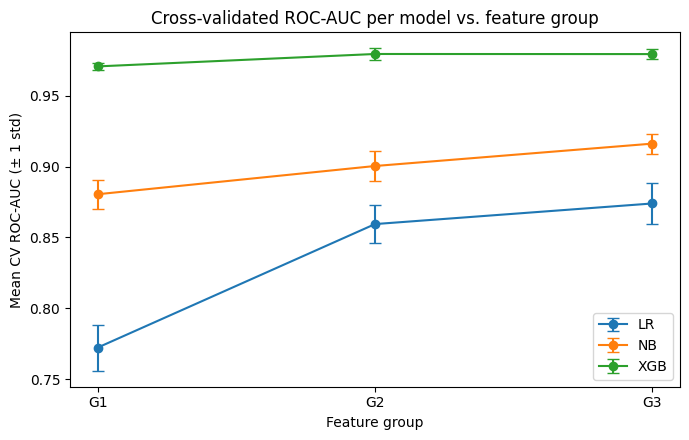

model,group,params,n_estimators,auc_mean,auc_std,f1_mean,f1_std
LR,G3,{'C': 100},nan,0.874010,0.014374,0.714504,0.030386
NB,G3,{'var_smoothing': 0.1},nan,0.916292,0.006979,0.683276,0.020478
XGB,G2,"{'max_depth': 3, 'learning_rate': 0.03}",804.000000,0.979628,0.003919,0.898822,0.009228


In [53]:
# plot: model's CV ROC-AUC vs features
plt.figure(figsize=(7, 4.5))
for model_name in ["LR", "NB", "XGB"]:
    sub = best_cells[best_cells["model"] == model_name].sort_values("group")
    plt.errorbar(sub["group"], sub["auc_mean"], yerr=sub["auc_std"],
                 marker="o", capsize=4, label=model_name)
plt.xlabel("Feature group")
plt.ylabel("Mean CV ROC-AUC (± 1 std)")
plt.title("Cross-validated ROC-AUC per model vs. feature group")
plt.legend()
plt.tight_layout()
plt.show()

# best group and hyperparameters per model across all groups (G1-G3)
best_per_model = cv_results.loc[cv_results.groupby("model")["auc_mean"].idxmax()]
display(best_per_model[["model", "group", "params", "n_estimators",
                        "auc_mean", "auc_std", "f1_mean", "f1_std"]]
        .style.hide(axis="index"))

In [49]:
'''
best hyperparameters per model restricted to G3. G3 is the best group for
LR and NB, and statistically very similar with G2 for XGBoost
(difference 0.000068 AUC ~ 50 times smaller than 1 std), so all three models
use the same G3 features on the test set for a fair comparison.
'''
FINAL_FEATURES = groups["G3"]

g3_results = cv_results[cv_results["group"] == "G3"]
best_per_model = g3_results.loc[g3_results.groupby("model")["auc_mean"].idxmax()]
display(best_per_model[["model", "group", "params", "n_estimators",
                        "auc_mean", "auc_std", "f1_mean", "f1_std"]]
        .style.hide(axis="index"))

model,group,params,n_estimators,auc_mean,auc_std,f1_mean,f1_std
LR,G3,{'C': 100},nan,0.874010,0.014374,0.714504,0.030386
NB,G3,{'var_smoothing': 0.1},nan,0.916292,0.006979,0.683276,0.020478
XGB,G3,"{'max_depth': 5, 'learning_rate': 0.03}",345.000000,0.979560,0.003525,0.903414,0.008111


#8. Model Algorithms

In [ ]:
# final feature set (G3) and the train/test data
X_train_final, y_train_final = train[G3], train["target"]
X_test_final,  y_test_final  = test[G3],  test["target"]

print(f"XGBoost scale_pos_weight = {SCALE_POS_WEIGHT:.2f}")

final_models, final_results, test_probs = {}, [], {}

XGBoost scale_pos_weight = 1.95


##8.1. Logistic Regression

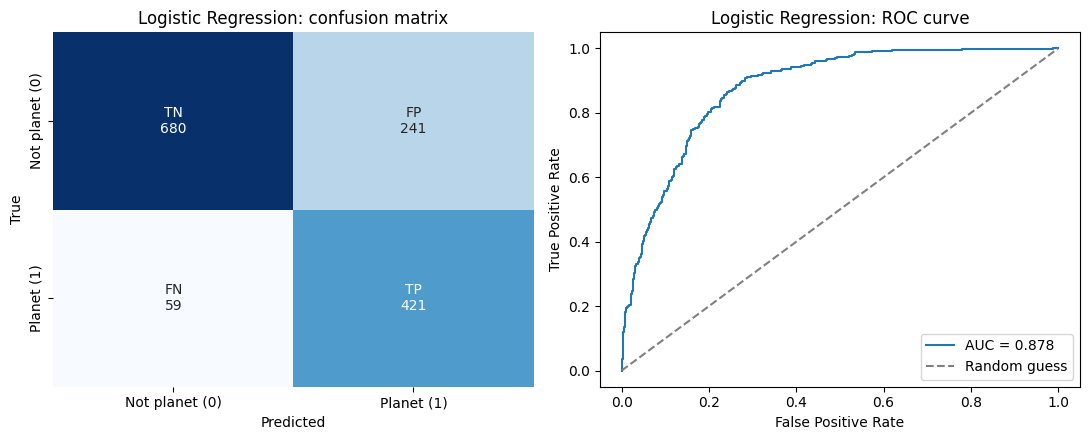

Model        Logistic Regression
TN                           680
FP                           241
FN                            59
TP                           421
Accuracy                0.785867
Precision               0.635952
Recall                  0.877083
F1                      0.737303
ROC-AUC                 0.878327


In [ ]:
# best cross-validation setting on G3: C = 100.
lr_final = build_pipeline("LR", C=100)
# refit on all training data
lr_final.fit(X_train_final, y_train_final)

# score once on the test set
# confusion matrix + ROC curve
lr_res = evaluate(lr_final, X_test_final, y_test_final, name="Logistic Regression")
print(pd.Series(lr_res).to_string())                    # TN, FP, FN, TP + five metrics

final_models["LR"] = lr_final
final_results.append(lr_res)
test_probs["LR"] = lr_final.predict_proba(X_test_final)[:, 1]

##8.2. Naive Bayes

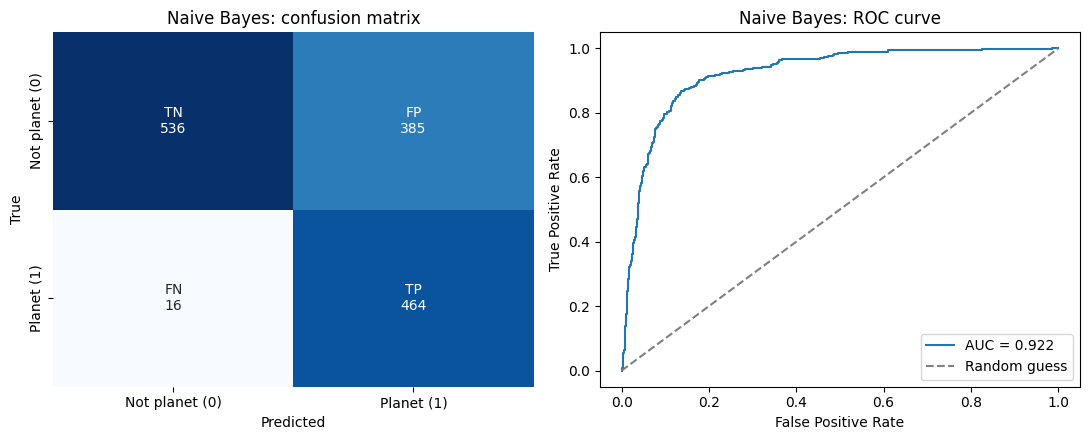

Model        Naive Bayes
TN                   536
FP                   385
FN                    16
TP                   464
Accuracy        0.713776
Precision       0.546525
Recall          0.966667
F1              0.698269
ROC-AUC         0.922272


In [ ]:
# best cross-validation setting on G3: var_smoothing = 0.1
nb_final = build_pipeline("NB", var_smoothing=0.1)
nb_final.fit(X_train_final, y_train_final)

nb_res = evaluate(nb_final, X_test_final, y_test_final, name="Naive Bayes")
print(pd.Series(nb_res).to_string())

final_models["NB"] = nb_final
final_results.append(nb_res)
test_probs["NB"] = nb_final.predict_proba(X_test_final)[:, 1]

##8.3. XGBoost

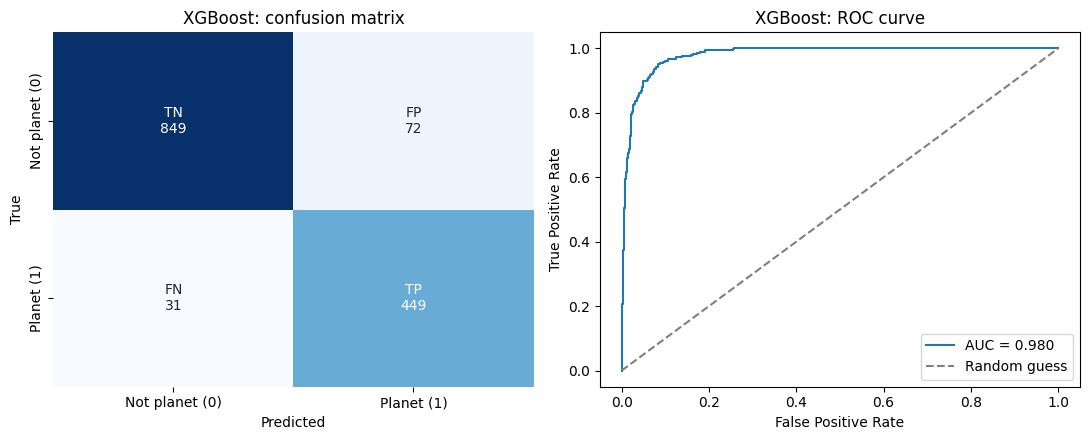

Model         XGBoost
TN                849
FP                 72
FN                 31
TP                449
Accuracy     0.926481
Precision    0.861804
Recall       0.935417
F1           0.897103
ROC-AUC      0.979961


In [ ]:
'''
best cross-validation setting on G3: depth 5, learning rate 0.03, 345 trees.

The number of trees was fixed from cross-validation, because early stopping on
the test set would leak test information into model selection.
'''

xgb_final = build_pipeline("XGB", max_depth=5, learning_rate=0.03, n_estimators=345)
xgb_final.fit(X_train_final, y_train_final)

xgb_res = evaluate(xgb_final, X_test_final, y_test_final, name="XGBoost")
print(pd.Series(xgb_res).to_string())

final_models["XGB"] = xgb_final
final_results.append(xgb_res)
test_probs["XGB"] = xgb_final.predict_proba(X_test_final)[:, 1]

#9. Comparison on the test set

In [54]:
# one row per model
comparison = (pd.DataFrame(final_results)
                .drop_duplicates(subset="Model", keep="last")
                .set_index("Model"))

metric_cols = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
display(comparison[["TN", "FP", "FN", "TP"] + metric_cols].round(3))

# best model per metric
print("\nBest model per metric:")
print(comparison[metric_cols].astype(float).idxmax().to_string())

,TN,FP,FN,TP,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,,,,,
Logistic Regression,680,241,59,421,0.786,0.636,0.877,0.737,0.878
Naive Bayes,536,385,16,464,0.714,0.547,0.967,0.698,0.922
XGBoost,849,72,31,449,0.926,0.862,0.935,0.897,0.980



Best model per metric:
Accuracy         XGBoost
Precision        XGBoost
Recall       Naive Bayes
F1               XGBoost
ROC-AUC          XGBoost


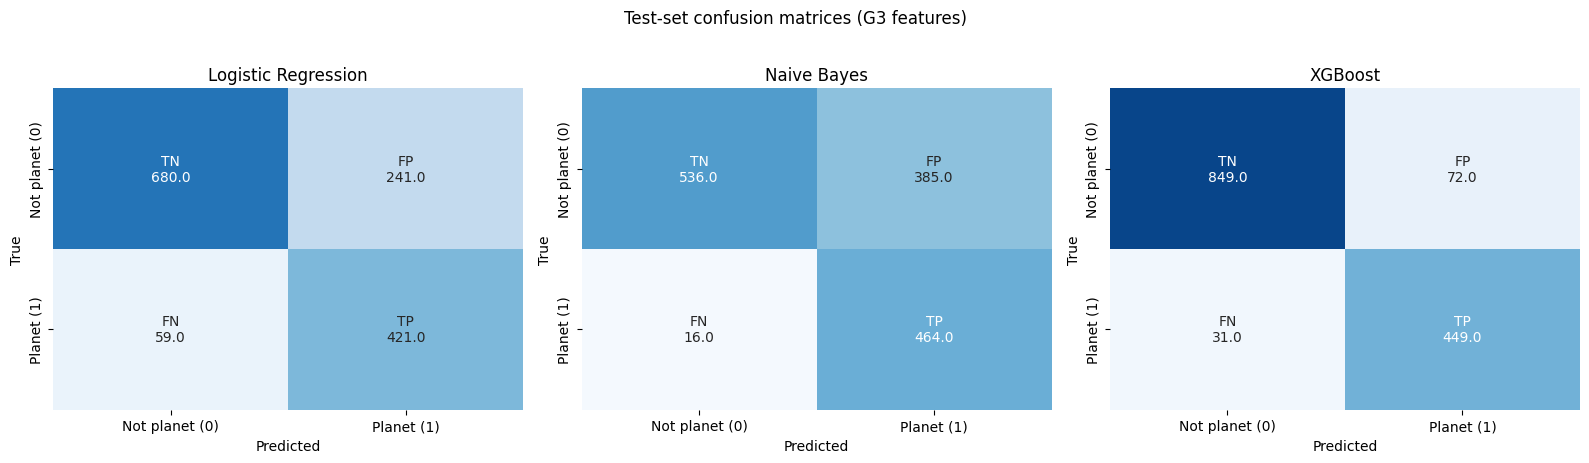

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, (model_name, row) in zip(axes, comparison.iterrows()):
    tn, fp, fn, tp = row["TN"], row["FP"], row["FN"], row["TP"]

    cell_text = [[f"TN\n{tn}", f"FP\n{fp}"],
                 [f"FN\n{fn}", f"TP\n{tp}"]]

    sns.heatmap([[tn, fp], [fn, tp]], annot=cell_text, fmt="", cbar=False,
                cmap="Blues", ax=ax,
                vmin=0, vmax=len(y_test_final) * 0.66,
                xticklabels=["Not planet (0)", "Planet (1)"],
                yticklabels=["Not planet (0)", "Planet (1)"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(model_name)

plt.suptitle("Test-set confusion matrices (G3 features)", y=1.02)
plt.tight_layout()
plt.show()

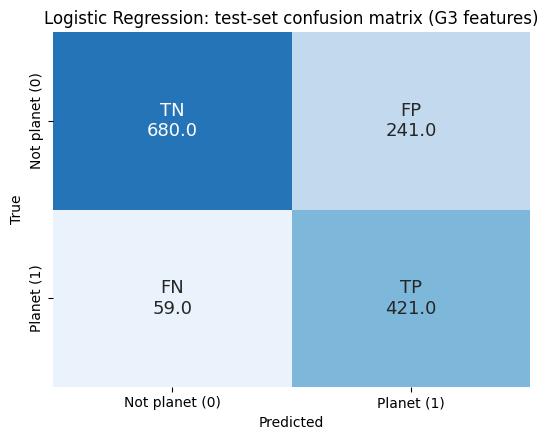

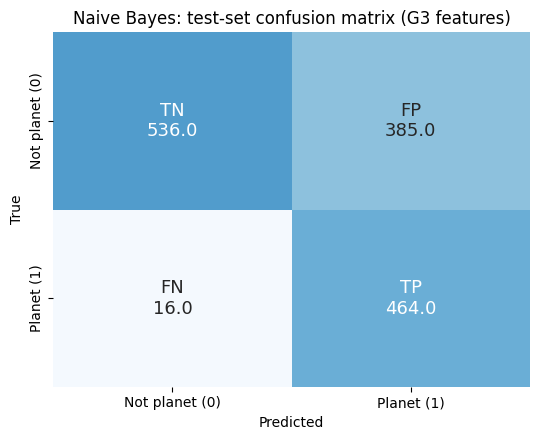

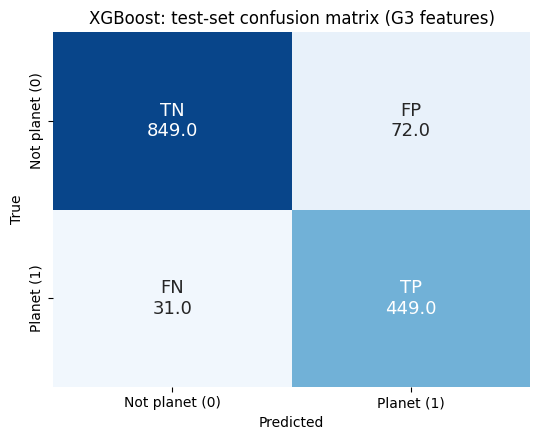

In [ ]:
'''# One separate figure per model
for model_name, row in comparison.iterrows():
    tn, fp, fn, tp = row["TN"], row["FP"], row["FN"], row["TP"]

    # cell layout: TN upper left, FP upper right, FN lower left, TP lower right
    cell_text = [[f"TN\n{tn}", f"FP\n{fp}"],
                 [f"FN\n{fn}", f"TP\n{tp}"]]

    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    sns.heatmap([[tn, fp], [fn, tp]], annot=cell_text, fmt="", cbar=False,
                cmap="Blues", ax=ax,
                # same color scale for all three, so shades stay comparable
                vmin=0, vmax=len(y_test_final) * 0.66,
                annot_kws={"size": 13},
                xticklabels=["Not planet (0)", "Planet (1)"],
                yticklabels=["Not planet (0)", "Planet (1)"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    ax.set_title(f"{model_name}: test-set confusion matrix (G3 features)")
    plt.tight_layout()
    plt.show()
'''

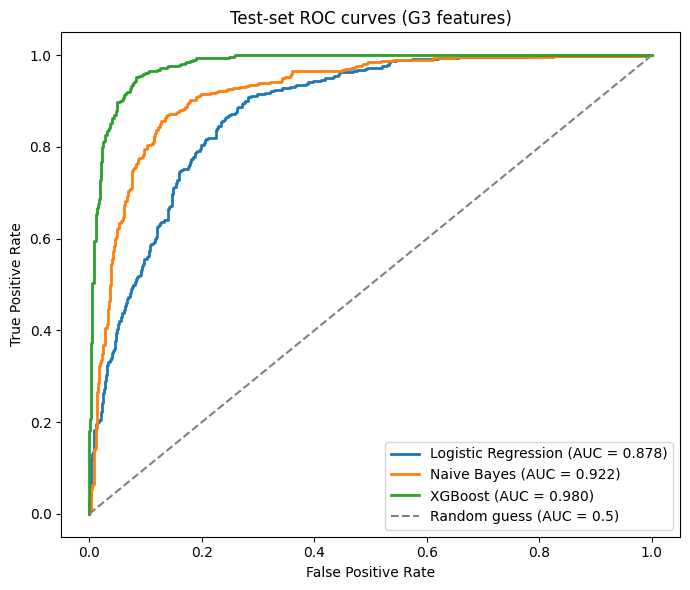

In [ ]:
plt.figure(figsize=(7, 6))

# one curve per model, using the test probabilities stored before
names = {"LR": "Logistic Regression", "NB": "Naive Bayes", "XGB": "XGBoost"}
for key, probs in test_probs.items():
    fpr, tpr, _ = metrics.roc_curve(y_test_final, probs)
    auc = metrics.roc_auc_score(y_test_final, probs)
    plt.plot(fpr, tpr, linewidth=2, label=f"{names[key]} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], "--", color="grey", label="Random guess (AUC = 0.5)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Test-set ROC curves (G3 features)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

#10. Comparison of Algorithms using Candidates subset

## 10.1. Scoring the CANDIDATE subset

**Setup:** The 2,262 CANDIDATE KOIs have no final label, so they were never used for training, tuning, or testing. Each one is scored with the three final G3 models, using the same 12 features, to give a probability of being a planet:

$$p_i^{(m)} = P\big(y_i = 1 \mid \mathbf{x}_i\big) \quad \text{from model } m \in \{\mathrm{LR},\ \mathrm{NB},\ \mathrm{XGB}\}$$

Each probability is converted to a hard label with the same 0.5 threshold used on the test set:

$$\hat{y}_i^{(m)} = \mathbb{1}\!\left[\,p_i^{(m)} \ge 0.5\,\right]$$

**External reference check:** NASA's `koi_score` is the Robovetter's confidence that a Threshold Crossing Event is a planet. It runs from $0$ (strong confidence of a false positive) to $1$ (strong confidence of a planet).

**Notes:**

- These counts are predictions of exoplanet by the models.
- Each model's $f^{(m)}$ is expected to reflect its test-set behavior at the 0.5 threshold. Naive Bayes had the highest recall and the most false positives on the test set, so it should call the largest share of candidates planets. XGBoost, the most precise, should be the most conservative.
- The 0.5 threshold was not tuned for candidates and Naive Bayes's probabilities are miscalibrated, so its counts depend heavily on that threshold. - Hence, I did a Spearman rank correlation for a fairer comparison since it uses order of candidates and not the probability values. In other words, Spearman rank checks if two models agree on which candidates are planets.

In [ ]:
# CANDIDATES subset uses the same G3 features as training
X_cand = candidates[G3]

# one row per candidate: identifiers + each model's P(planet)
scores = pd.DataFrame(index=candidates.index)
# NASA Kepler Robovetter disposition score
'''
a metric ranging from 0.0 to 1.0 that indicates the algorithm's confidence
in its classification of a Threshold Crossing Event (TCS).
1.0: Strong confidence that the event is a Planet
0.0: Strong confidence that the event is a False Positive
'''
scores["kepoi_name"] = vetting.loc[candidates.index, "kepoi_name"]
scores["koi_score"]  = vetting.loc[candidates.index, "koi_score"]

for key, model in final_models.items():
    scores[f"p_{key}"] = model.predict_proba(X_cand)[:, 1]

# label threshold at 0.5 and number of candidates classified as exoplanet by each model
for key in final_models:
    scores[f"is_planet_{key}"] = (scores[f"p_{key}"] >= 0.5).astype(int)
    n = scores[f"is_planet_{key}"].sum()
    print(f"{key}: {n} of {len(scores)} candidates classified as planets ({n/len(scores):.1%})")

LR: 1519 of 2262 candidates classified as planets (67.2%)
NB: 1907 of 2262 candidates classified as planets (84.3%)
XGB: 871 of 2262 candidates classified as planets (38.5%)


##10.2. Spearman Rank Correlation (CS146 application)

**Definition:** Spearman's $\rho$ is the Pearson correlation between the ranks of two score vectors. For two scores on $n$ candidates, let $r_i$ and $q_i$ be the rank of candidate $i$ under each score, with $\bar r$ and $\bar q$ the mean ranks:

$$\rho = \frac{\sum_{i=1}^{n}(r_i - \bar r)(q_i - \bar q)}{\sqrt{\sum_{i=1}^{n}(r_i - \bar r)^2}\;\sqrt{\sum_{i=1}^{n}(q_i - \bar q)^2}}$$

When there are no ties, this reduces to

$$\rho = 1 - \frac{6\sum_{i=1}^{n} d_i^{2}}{n\,(n^{2}-1)}, \qquad d_i = r_i - q_i$$

where $d_i$ is the difference between candidate $i$'s ranks under the two scores. A value of $\rho = 1$ means the two scores order the candidates identically, $\rho = 0$ means no monotonic relationship, and $\rho = -1$ means reversed order.

**Output:** A $4 \times 4$ matrix of pairwise $\rho$ values between $p^{\rm LR}$, $p^{\rm NB}$, $p^{\rm XGB}$, and NASA's `koi_score`. Pairs with a missing `koi_score` are dropped pair by pair. For each model, a significance test of $H_0:\rho = 0$ is also reported, with $p$-value and sample size $n$ (the number of candidates that have a `koi_score`).

**Notes:**
- Spearman depends only on ordering so NB's miscalibrated probabilities and the untuned 0.5 threshold do not affect it.
- A high $\rho$ means the models rank candidates similarly. It measures **consistency** among models and not how accurate they are.
- **Model vs `koi_score`** comparison is also a supporting evidence since the Robovetter is independent from the models.
- **Significance** With $n$ in the thousands, even a small $\rho$ gives a tiny $p$-value, so judge agreement by the size of $\rho$, not by $p$.
- `koi_score` values pile up near 0 or 1, which affects $d_i$ and $\rho$. However, spearman rank computes pearson correlation on average-tied ranks. This means that the reported $\rho$ is correct.

**Limitations:**

- `koi_score` was produced with information partly shared with the labels (the Robovetter's output feeds the dispositions). This means that a model trained on those labels can agree with `koi_score` partly since both refer back to the same vetting process. This comparison does not show anything on model's ability to find actual exoplanet.
- Rank agreement says nothing about calibration or about the 0.5 decision threshold.

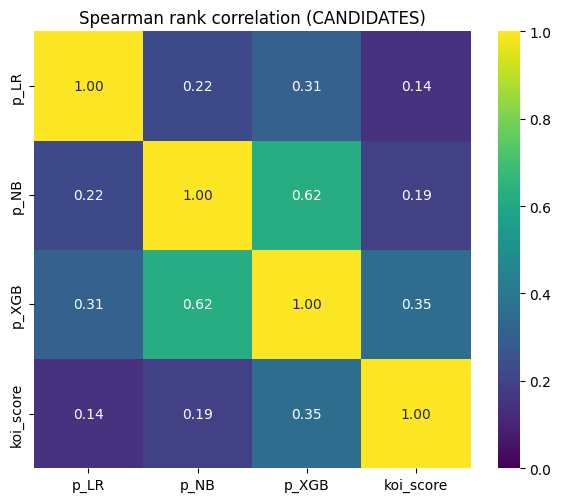

Spearman rho vs NASA koi_score:
  LR: rho = 0.143  (p = 2.0e-09, n = 1755)
  NB: rho = 0.194  (p = 2.8e-16, n = 1755)
  XGB: rho = 0.355  (p = 3.2e-53, n = 1755)


In [ ]:
# pairwise Spearman rank correlation between the three models and NASA's koi_score.
rank_cols = ["p_LR", "p_NB", "p_XGB", "koi_score"]
spearman_matrix = scores[rank_cols].corr(method="spearman")

plt.figure(figsize=(6, 5))
sns.heatmap(spearman_matrix, annot=True, fmt=".2f", cmap="viridis",
            vmin=0, vmax=1, square=True)
plt.title("Spearman rank correlation (CANDIDATES)")
plt.tight_layout()
plt.show()

print("Spearman rho vs NASA koi_score:")
for key in ["LR", "NB", "XGB"]:
    sub = scores[[f"p_{key}", "koi_score"]].dropna()
    rho, pval = spearmanr(sub[f"p_{key}"], sub["koi_score"])
    print(f"  {key}: rho = {rho:.3f}  (p = {pval:.1e}, n = {len(sub)})")

For each candidate, I counted how many of the three models call it a planet, $V_i = \sum_{m \in \{\mathrm{LR},\,\mathrm{NB},\,\mathrm{XGB}\}} \hat{y}_i^{(m)}$ with $V_i \in \{0, 1, 2, 3\}$, where $V_i \in \{0, 3\}$ is a unanimous decision and $V_i \in \{1, 2\}$ is a split decision. To locate the strongest disagreement between the most accurate and the most overconfident model, I also computed $\Delta_i = p_i^{\rm XGB} - p_i^{\rm NB}$ and inspected the candidates with the most negative values (NB says planet, XGB says not a planet) and the most positive values (the reverse), together with their planet radius, impact parameter, duration ratio, and SNR.

In [ ]:
# code to see where the models disagree
# votes: how many of the 3 models call each candidate a planet (0 to 3)
scores["votes"] = scores[["is_planet_LR", "is_planet_NB", "is_planet_XGB"]].sum(axis=1)

print("0 or 3 = unanimous, 1 or 2 = split decision")

vote_table = (scores["votes"].value_counts().sort_index()
              .rename_axis("Votes").reset_index(name="Candidates"))
vote_table["Meaning"] = vote_table["Votes"].map(
    {0: "all three say: not planet", 1: "split", 2: "split", 3: "all three say: planet"})
display(vote_table)
# largest disagreements between the best model (XGBoost) and the most overconfident one (NB)
scores["XGB_minus_NB"] = scores["p_XGB"] - scores["p_NB"]
inspect_cols = ["kepoi_name", "p_LR", "p_NB", "p_XGB", "koi_score"]
phys = candidates[["log_prad", "koi_impact", "log_dur_ratio", "log_snr"]]

0 or 3 = unanimous, 1 or 2 = split decision


,Votes,Candidates,Meaning
0,0,190,all three say: not planet
1,1,524,split
2,2,871,split
3,3,677,all three say: planet


To see where Naive Bayes and XGBoost disagree most, I listed the 10 candidates with the most negative $\Delta_i = p_i^{\rm XGB} - p_i^{\rm NB}$, alongwith their planet radius, impact parameter, duration ratio, and SNR.

In [ ]:
print("Naive Bayes says planet, XGBoost says not a planet (10 most negative case candidates):")
display(scores.nsmallest(10, "XGB_minus_NB")[inspect_cols].join(phys).round(3))

Naive Bayes says planet, XGBoost says not a planet (10 most negative case candidates):


,kepoi_name,p_LR,p_NB,p_XGB,koi_score,log_prad,koi_impact,log_dur_ratio,log_snr
8386,K07093.01,0.670,0.995,0.005,0.433,0.149,0.711,-0.296,0.954
7094,K05954.01,0.736,0.997,0.008,NaN,-0.027,0.495,-0.250,0.845
7099,K05959.01,0.476,0.992,0.003,NaN,0.241,0.801,-0.184,0.806
6402,K04991.01,0.597,0.991,0.003,NaN,0.320,0.055,-0.325,0.875
7121,K05851.01,0.561,0.990,0.002,NaN,0.338,0.214,-0.219,0.949
7734,K04838.02,0.011,0.993,0.006,0.804,0.882,1.101,0.161,0.875
4388,K04591.01,0.480,0.994,0.008,0.980,-0.051,0.385,0.095,1.037
7053,K05913.01,0.393,0.998,0.011,NaN,0.294,0.390,-0.266,0.799
8394,K07223.01,0.691,0.992,0.006,0.947,0.201,0.673,-0.110,0.991
7090,K05950.01,0.761,0.997,0.011,NaN,0.000,0.090,-0.258,0.863


In [ ]:
print("XGBoost says planet, Naive Bayes says not a planet (10 most negative case candidates):")
display(scores.nlargest(10, "XGB_minus_NB")[inspect_cols].join(phys).round(3))

XGBoost says planet, Naive Bayes says not a planet (10 most negative case candidates):


,kepoi_name,p_LR,p_NB,p_XGB,koi_score,log_prad,koi_impact,log_dur_ratio,log_snr
3248,K00075.01,0.646,0.085,0.969,1.000,1.007,0.539,-0.037,2.480
7370,K06217.01,0.142,0.058,0.929,0.956,0.647,0.010,-0.106,1.250
346,K00972.01,0.203,0.000,0.830,0.632,0.916,0.042,-0.523,2.427
716,K01246.01,0.746,0.145,0.957,1.000,0.759,0.033,-0.614,1.403
3298,K00076.01,0.056,0.119,0.904,0.000,1.014,0.019,-0.274,1.861
3399,K00099.01,0.961,0.081,0.844,NaN,0.494,0.260,0.010,1.977
1228,K01466.01,0.919,0.179,0.909,0.998,1.035,0.000,-0.059,2.375
7199,K06093.02,0.403,0.182,0.902,0.479,0.652,0.194,-0.236,1.164
5052,K03398.02,0.311,0.241,0.927,0.996,0.901,0.043,-0.374,1.398
4382,K04519.01,0.788,0.019,0.688,0.898,0.776,0.243,-0.751,1.064


**Notes:**
- The code below ranks every candidate under each of the three models with rank 1 = highest planet probability.
- The three ranks are averaged in `mean_rank`
- This is done so that Naive Bayes' extreme probabilities cannot affect the combined score (hence I averaged by rank and not probabilities)
- Then, the candidates for which all the three models clasify as exoplanet are sorted out by `mean_rank`
- I have also transformed the log-space variables into their physical unit form.  

In [ ]:
for key in ["LR", "NB", "XGB"]:
    scores[f"rank_{key}"] = scores[f"p_{key}"].rank(ascending=False)  # 1 = most planet-like
scores["mean_rank"] = scores[["rank_LR", "rank_NB", "rank_XGB"]].mean(axis=1)

# Top candidates: all three models agree it is a planet, sorted by mean rank
consensus = scores[scores["votes"] == 3].sort_values("mean_rank")

# readable physical units
consensus = consensus.join(pd.DataFrame({
    "radius_Rearth": 10 ** candidates["log_prad"],
    "period_days":   10 ** candidates["log_period"],
    "insol_Earth":   10 ** candidates["log_insol"],
}))

print(f"Unanimous votes as exoplanet for: {len(consensus)} candidates")
print("\nTop 15 consensus candidates:")
display(consensus[["kepoi_name", "p_LR", "p_NB", "p_XGB", "mean_rank", "koi_score",
                   "radius_Rearth", "period_days", "insol_Earth"]].head(15).round(3))

Unanimous votes as exoplanet for: 677 candidates

Top 15 consensus candidates:


,kepoi_name,p_LR,p_NB,p_XGB,mean_rank,koi_score,radius_Rearth,period_days,insol_Earth
1581,K01934.01,0.917,1.000,0.982,41.000,1.000,2.11,28.783,9.09
1739,K02117.01,0.887,1.000,0.984,50.000,1.000,1.84,13.360,17.30
907,K01408.01,0.930,0.999,0.987,59.667,1.000,1.36,14.534,7.34
1744,K02191.01,0.939,0.999,0.989,63.333,1.000,1.15,8.848,12.48
991,K01358.02,0.857,1.000,0.984,72.333,0.999,1.92,8.743,40.33
851,K01276.01,0.850,1.000,0.993,74.000,1.000,2.57,22.790,38.27
3484,K00704.01,0.861,1.000,0.985,78.667,1.000,2.47,18.396,27.09
6043,K01871.02,0.880,0.999,0.988,78.667,1.000,2.26,32.376,5.61
2086,K02503.01,0.923,1.000,0.968,82.667,1.000,0.96,14.820,21.92
2616,K02694.02,0.912,1.000,0.963,99.333,1.000,1.83,6.566,86.27


- printing of missing candidates
- There were candidates for which the Kepler pipeline produced no transit fit due to missing `koi_depth` and the other fitted parameters. Those could not be used by any model, so the 105 such KOIs were dropped during feature grouping and are reported as unscorable.
- I could not apply median subsitution or anything else because these rows missed almost everything.
- I did not estimate using host star properties since that would involve more computation → these KOIs need more data.

In [ ]:
# candidates with no transit fit (refer back to Feature Grouping section)
unscorable_cand = unscorable[unscorable["koi_disposition"] == "CANDIDATE"]
print(f"Unscorable candidates (no fitted parameters): {len(unscorable_cand)}")
print("\n10 examples of unscorable candidates:")
display(unscorable_cand.head(10))

Unscorable candidates (no fitted parameters): 105

10 examples of unscorable candidates:


,kepid,kepoi_name,kepler_name,koi_disposition,koi_pdisposition,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,koi_fpflag_ec,koi_period,koi_period_err1,koi_period_err2,koi_time0bk,koi_time0bk_err1,koi_time0bk_err2,koi_impact,koi_impact_err1,koi_impact_err2,koi_duration,koi_duration_err1,koi_duration_err2,koi_depth,koi_depth_err1,koi_depth_err2,koi_prad,koi_prad_err1,koi_prad_err2,koi_teq,koi_teq_err1,koi_teq_err2,koi_insol,koi_insol_err1,koi_insol_err2,koi_model_snr,koi_tce_plnt_num,koi_tce_delivname,koi_steff,koi_steff_err1,koi_steff_err2,koi_slogg,koi_slogg_err1,koi_slogg_err2,koi_srad,koi_srad_err1,koi_srad_err2,ra,dec,koi_kepmag
479,3447722,K01198.04,NaN,CANDIDATE,CANDIDATE,NaN,0,0,0,0,1.008617,NaN,NaN,132.109479,NaN,NaN,NaN,NaN,NaN,0.91,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,292.47971,38.514919,15.319
746,10794087,K01316.02,NaN,CANDIDATE,CANDIDATE,NaN,0,0,0,0,12.376793,NaN,NaN,143.378718,NaN,NaN,NaN,NaN,NaN,3.85,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,290.55237,48.126263,11.926
822,11336883,K01445.03,NaN,CANDIDATE,CANDIDATE,NaN,0,0,0,0,20.019596,NaN,NaN,150.836218,NaN,NaN,NaN,NaN,NaN,7.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,283.93680,49.110329,12.320
970,7363829,K01356.01,NaN,CANDIDATE,CANDIDATE,NaN,0,0,0,0,384.025707,NaN,NaN,335.816169,NaN,NaN,NaN,NaN,NaN,14.56,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,292.11990,42.931679,15.206
1101,7199906,K01739.01,NaN,CANDIDATE,CANDIDATE,NaN,0,0,0,0,220.656512,NaN,NaN,172.427859,NaN,NaN,NaN,NaN,NaN,7.82,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,291.65009,42.700779,15.129
1242,5526717,K01677.02,NaN,CANDIDATE,CANDIDATE,NaN,0,0,0,0,8.511701,NaN,NaN,131.755744,NaN,NaN,NaN,NaN,NaN,2.90,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,289.67935,40.700459,14.279
1502,9411166,K01922.02,NaN,CANDIDATE,CANDIDATE,NaN,0,0,0,0,15.095213,NaN,NaN,139.474359,NaN,NaN,NaN,NaN,NaN,3.41,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,294.61365,45.984619,15.356
1602,10005788,K01940.02,NaN,CANDIDATE,CANDIDATE,NaN,0,0,0,0,6.736797,NaN,NaN,136.404341,NaN,NaN,NaN,NaN,NaN,2.36,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,289.35202,46.973728,15.389
1673,7033233,K02339.02,NaN,CANDIDATE,CANDIDATE,NaN,0,0,0,0,65.187037,NaN,NaN,177.620888,NaN,NaN,NaN,NaN,NaN,5.44,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,291.66928,42.590710,15.130
1889,4247991,K02311.01,NaN,CANDIDATE,CANDIDATE,NaN,0,0,0,0,191.864193,NaN,NaN,294.470360,NaN,NaN,NaN,NaN,NaN,4.90,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,287.24118,39.332760,12.570
